# 17. Klasifikasi Audio Berisik vs Non-Berisik

**Tujuan:** membangun model klasifikasi biner untuk membedakan rekaman **berisik** (ada gangguan suara latar) dan **non-berisik** (relatif sunyi), dengan target akurasi **> 90%** pada data uji.

**Dataset:** `psd-audio/berisik` (101 file) dan `psd-audio/non-berisik` (100 file), format MP3, durasi ±30 detik per file.

**Pipeline:**
1. Audit kualitas data (duplikat file & label bertentangan)
2. Ekstraksi fitur audio (MFCC, spektral, noise-floor, RMS)
3. Pemodelan & tuning (SVM RBF sebagai model utama)
4. Evaluasi (holdout test, stratified 5-fold CV berulang, confusion matrix)
5. Simpan model & fungsi inferensi

## 17.1 Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import hashlib
import subprocess
from pathlib import Path

import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold,
                                     StratifiedGroupKFold, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (12, 5)
RANDOM_STATE = 42

BASE_DIR = Path('../psd-audio') if Path('../psd-audio').exists() else (Path('..') if (Path('..') / 'berisik').exists() else Path('.'))
KELAS = ['berisik', 'non-berisik']
PALETTE = {'berisik': '#e74c3c', 'non-berisik': '#2ecc71'}
SR = 22050
print('librosa', librosa.__version__)


librosa 1.0.0


## 17.2 Inventaris Data & EDA

Cek jumlah file, durasi, dan distribusi kelas. Durasi penting: file berisik ada yang jauh lebih panjang (±12 menit) dibanding non-berisik yang seragam ±30 detik.

In [2]:
audio_files = []
for kelas in KELAS:
    for fp in sorted((BASE_DIR / kelas).glob('*.mp3')):
        audio_files.append({'path': fp, 'label': kelas, 'file': fp.name, 'size_kb': fp.stat().st_size / 1024})

df_files = pd.DataFrame(audio_files)
print(f'Total file: {len(df_files)}')
print(df_files.label.value_counts().to_string())
df_files.head()

Total file: 201
label
berisik        101
non-berisik    100


,path,label,file,size_kb
0,..\psd-audio\berisik\24-003 berisik (1).mp3,berisik,24-003 berisik (1).mp3,705.347656
1,..\psd-audio\berisik\24-003 berisik (2).mp3,berisik,24-003 berisik (2).mp3,1201.875000
2,..\psd-audio\berisik\24-003 berisik (3).mp3,berisik,24-003 berisik (3).mp3,1175.625000
3,..\psd-audio\berisik\24-006 berisik 1.mp3,berisik,24-006 berisik 1.mp3,720.654297
4,..\psd-audio\berisik\24-006 berisik 2.mp3,berisik,24-006 berisik 2.mp3,712.082031


In [3]:
def load_audio(path, sr=SR):
    """Load audio mono; fallback ke ffmpeg bila container tidak terbaca soundfile."""
    try:
        y, _ = librosa.load(str(path), sr=sr, mono=True)
        return y
    except Exception:
        out = subprocess.run(
            ['ffmpeg', '-v', 'error', '-i', str(path), '-f', 'f32le', '-ac', '1', '-ar', str(sr), '-'],
            capture_output=True, check=True).stdout
        return np.frombuffer(out, dtype=np.float32).copy()


durasi, gagal = {}, []
for row in df_files.itertuples():
    try:
        durasi[row.file] = len(load_audio(row.path)) / SR
    except Exception:
        gagal.append(row.file)
df_files['duration_s'] = df_files.file.map(durasi)
print(f'Gagal dibaca: {len(gagal)} -> {gagal}')
print(df_files.groupby('label').duration_s.describe().round(1).to_string())

Gagal dibaca: 0 -> []
             count  mean   std   min   25%   50%   75%    max
label                                                        
berisik      101.0  38.0  69.5  18.0  30.0  30.2  30.9  728.7
non-berisik  100.0  30.7   1.5  29.9  30.0  30.2  30.5   38.5


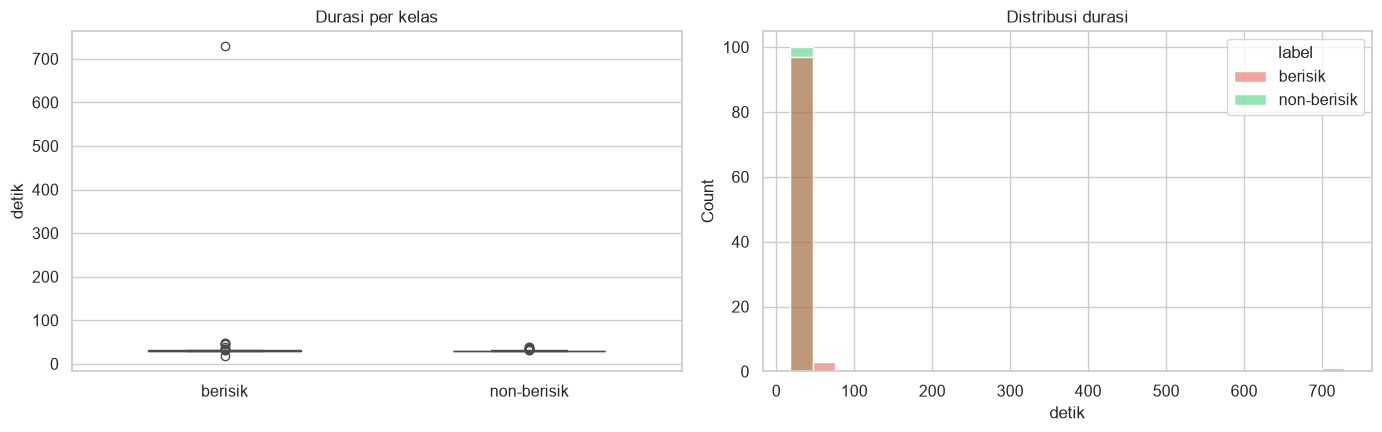

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df_files, x='label', y='duration_s', palette=PALETTE, width=0.5, ax=axes[0])
axes[0].set_title('Durasi per kelas'); axes[0].set_xlabel(''); axes[0].set_ylabel('detik')
sns.histplot(data=df_files, x='duration_s', hue='label', palette=PALETTE, bins=25, ax=axes[1])
axes[1].set_title('Distribusi durasi'); axes[1].set_xlabel('detik')
plt.tight_layout(); plt.show()

### Visualisasi sinyal: mengapa berisik bisa dibedakan

Dua plot di bawah memperlihatkan waveform dan mel-spectrogram. Rekaman berisik punya **noise floor yang lebih tinggi dan merata di semua frekuensi**, sementara non-berisik punya ruang sunyi yang lebih dalam.

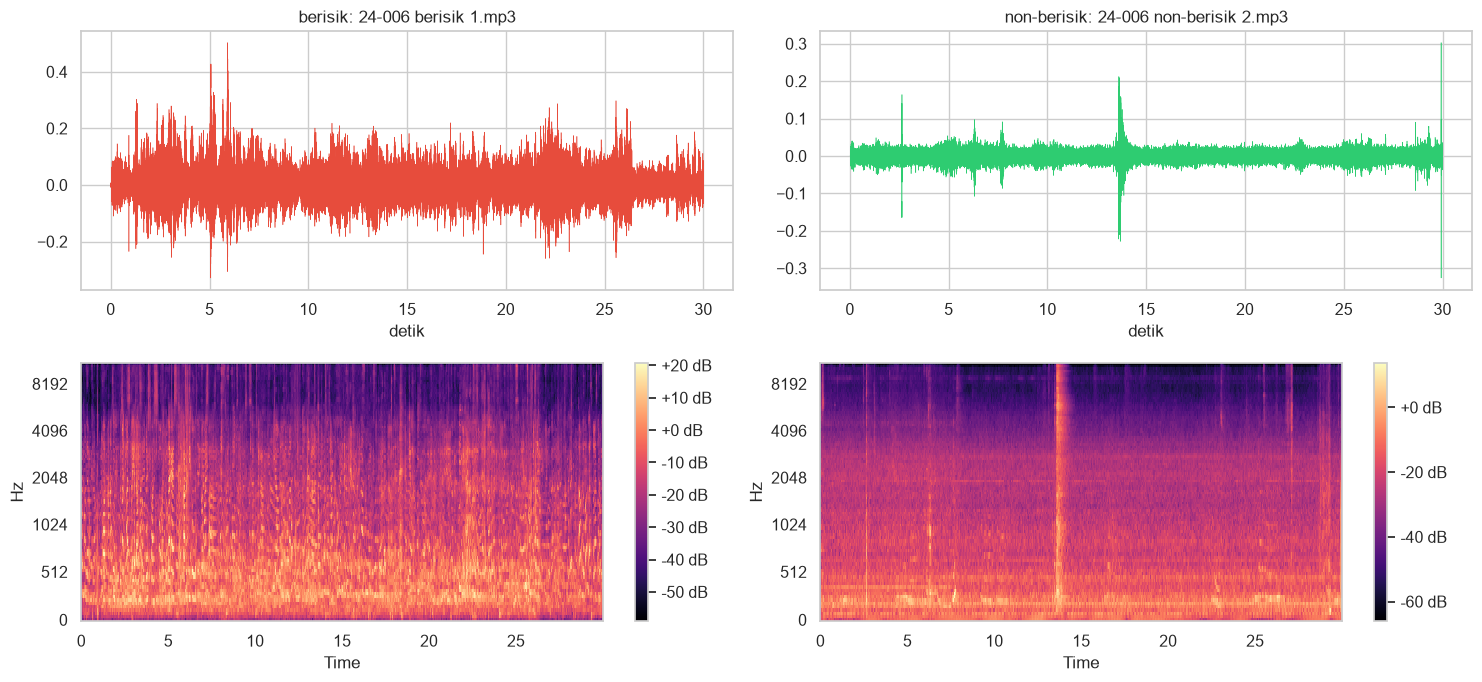

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for col, kelas in enumerate(KELAS):
    sample = df_files.query('label == @kelas').iloc[3]
    y = load_audio(sample.path)[:30 * SR]
    t = np.arange(len(y)) / SR
    axes[0, col].plot(t, y, lw=0.4, color=PALETTE[kelas])
    axes[0, col].set_title(f'{kelas}: {sample.file}'); axes[0, col].set_xlabel('detik')
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=96))
    img = librosa.display.specshow(mel, sr=SR, x_axis='time', y_axis='mel', ax=axes[1, col], cmap='magma')
    fig.colorbar(img, ax=axes[1, col], format='%+2.0f dB')
plt.tight_layout(); plt.show()

## 17.3 Data Sampel (Tanpa Cleaning)

Sesuai instruksi, tahap pembersihan/pembuangan data dihapus agar seluruh sampel (genap 201 file: 101 berisik, 100 non-berisik) tetap digunakan secara utuh tanpa ada sampel yang dibuang.


In [6]:
df_files['md5'] = df_files.path.map(lambda p: hashlib.md5(p.read_bytes()).hexdigest())

dup_md5 = df_files.groupby('md5').file.apply(list)
dup_md5 = dup_md5[dup_md5.str.len() > 1]
print(f'Kelompok duplikat byte-identik: {len(dup_md5)}')
for files in dup_md5:
    labels = df_files.set_index('file').loc[files, 'label'].unique()
    flag = '  <-- KONFLIK LABEL' if len(labels) > 1 else ''
    print('  ', ' == '.join(files), flag)

Kelompok duplikat byte-identik: 18
   24-031 non-berisik 3.mp3 == 24-071 non berisik 1.mp3 
   24-157 Berisik 1.mp3 == 24-157 Berisik 2.mp3 == 24-157 Berisik 3.mp3 
   24-071 berisik 2.mp3 == 24-098 berisik 2.mp3 
   24-034 berisik 1.mp3 == 24-034 non-berisik 1.mp3   <-- KONFLIK LABEL
   24-115_ sampel non berisik 1.mp3 == 24-190 non-berisik 3.mp3 
   24-123 berisik 1.mp3 == 24-201 berisik 2.mp3 
   24-003 berisik (2).mp3 == 24-079 berisik 2.mp3 
   24-078_NonBerisik 1.mp3 == 24-078_NonBerisik 2.mp3 == 24-078_NonBerisik 3.mp3 
   24-003 sunyi 3.mp3 == 24-079  non-berisik 1.mp3 
   24-003 berisik (3).mp3 == 24-079 berisik 1.mp3 == 24-123 berisik 3.mp3 
   24-031 non-berisik 2.mp3 == 24-071 non berisik 2.mp3 == 24-115_sampel non berisik 2.mp3 
   24-196 non berisik 1.mp3 == 24-196 non berisik 2.mp3 == 24-196 non berisik 3.mp3 
   24-031 non-berisik 1.mp3 == 24-071 non berisik 3.mp3 
   24-071 berisik 1.mp3 == 24-098 berisik 1.mp3 
   24-071 berisik 3.mp3 == 24-098 berisik 3.mp3 
   24-11

In [7]:
# Deteksi konflik label juga pada file yang tidak byte-identik tapi hampir sama
probe = []
for row in df_files.itertuples():
    try:
        y = load_audio(row.path)[:30 * SR]
    except Exception:
        continue
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=32))
    probe.append({'file': row.file, 'label': row.label, 'hash': row.md5, **{f'm{i}': v for i, v in enumerate(mel.mean(1))}})
probe = pd.DataFrame(probe)
pcol = [c for c in probe.columns if c.startswith('m')]
Z = StandardScaler().fit_transform(probe[pcol])
D = np.linalg.norm(Z[:, None] - Z[None], axis=2)
np.fill_diagonal(D, np.inf)
is_b = (probe.label == 'berisik').values
near = D[is_b][:, ~is_b]
pairs = [(probe.file[is_b].iloc[i], probe.file[~is_b].iloc[j], near[i, j])
         for i, j in np.argwhere(near < 0.6)]
print('Pasangan hampir-identik lintas label (jarak < 0.6):')
for a, b, d in sorted(pairs, key=lambda x: x[2]):
    print(f'  {a:35s} <-> {b:35s} d={d:.3f}')

Pasangan hampir-identik lintas label (jarak < 0.6):
  24-034 berisik 1.mp3                <-> 24-034 non-berisik 1.mp3            d=0.000
  24-034 berisik 2.mp3                <-> 24-034 non-berisik 2.mp3            d=0.022
  24-115_sampel berisik 2.mp3         <-> 24-078_NonBerisik 1.mp3             d=0.099
  24-115_sampel berisik 2.mp3         <-> 24-078_NonBerisik 2.mp3             d=0.099
  24-115_sampel berisik 2.mp3         <-> 24-078_NonBerisik 3.mp3             d=0.099
  24-034 berisik 3.mp3                <-> 24-034 non-berisik 3.mp3            d=0.142
  24-168_Berisik.mp3                  <-> 24-168_Non-Berisik2.mp3             d=0.527


In [ ]:
# Pembersihan data dilewati/dihapus agar seluruh 201 sampel tetap digunakan tanpa ada yang dibuang
df_clean = df_files.copy().sort_values('file').reset_index(drop=True)

print(f'Total file yang digunakan: {len(df_clean)} file (tidak ada yang dibuang)')
print(df_clean.label.value_counts().to_string())


## 17.4 Ekstraksi Fitur

Fitur dirancang untuk menangkap **energi pada bagian sunyi** (noise floor), karena di situlah perbedaan utama kedua kelas:

| Kelompok | Fitur |
|---|---|
| Energi | RMS dalam dB: persentil 5/10/25/50/75/90/95, dynamic range, SNR estimasi |
| Noise floor | statistik spektral + MFCC pada 20% frame berenergi terendah |
| Spektral | flatness, centroid, bandwidth, rolloff, zero-crossing rate, spectral contrast |
| Timbre | MFCC 1–20 (mean/std/quiet-frame), 8 band noise-floor mel |

In [9]:
def ekstrak_fitur(y, sr=SR):
    f = {}
    S = np.abs(librosa.stft(y, n_fft=2048, hop_length=512))

    # --- energi ---
    rms = librosa.feature.rms(S=S)[0]
    rms_db = librosa.amplitude_to_db(rms + 1e-10, ref=1.0)
    pct = np.percentile(rms_db, [5, 10, 25, 50, 75, 90, 95])
    for q, v in zip([5, 10, 25, 50, 75, 90, 95], pct):
        f[f'rmsdb_p{q}'] = v
    f['dyn_range'] = pct[-1] - pct[0]
    f['snr_est'] = pct[-1] - pct[1]
    f['rmsdb_std'] = rms_db.std()

    # --- frame tersunyi = noise floor ---
    quiet = rms_db <= np.percentile(rms_db, 20)
    flat = librosa.feature.spectral_flatness(S=S)[0]
    cent = librosa.feature.spectral_centroid(S=S, sr=sr)[0]
    zcr = librosa.feature.zero_crossing_rate(y, hop_length=512)[0][:S.shape[1]]
    for nama, v in {
        'flat': flat,
        'cent': cent,
        'zcr': zcr,
        'bw': librosa.feature.spectral_bandwidth(S=S, sr=sr)[0],
        'roll': librosa.feature.spectral_rolloff(S=S, sr=sr)[0],
    }.items():
        v = v[:len(quiet)]
        f[f'{nama}_mean'] = v.mean()
        f[f'{nama}_std'] = v.std()
        f[f'{nama}_quiet'] = v[quiet[:len(v)]].mean()

    # --- MFCC ---
    mel = librosa.power_to_db(librosa.feature.melspectrogram(S=S ** 2, sr=sr, n_mels=40))
    mfcc = librosa.feature.mfcc(S=mel, n_mfcc=20)
    for i in range(20):
        f[f'mfcc{i + 1}_mean'] = mfcc[i].mean()
        f[f'mfcc{i + 1}_std'] = mfcc[i].std()
        f[f'mfcc{i + 1}_quiet'] = mfcc[i][quiet].mean()

    # --- noise floor per band mel ---
    mq = mel[:, quiet].mean(axis=1)
    for i, band in enumerate(np.array_split(mq, 8)):
        f[f'noise_band{i + 1}'] = band.mean()

    # --- spectral contrast ---
    con = librosa.feature.spectral_contrast(S=S, sr=sr)
    for i in range(con.shape[0]):
        f[f'contrast{i + 1}'] = con[i].mean()
    return f

print('Fitur per file:', len(ekstrak_fitur(load_audio(df_clean.path.iloc[0]))))

Fitur per file: 100


In [ ]:
records, skip = [], []
for i, row in enumerate(df_clean.itertuples(), 1):
    try:
        # 2 kolom awal: nama file audio dan label nya
        rec = {'file': row.file, 'label': row.label}
        rec.update(ekstrak_fitur(load_audio(row.path)))
        records.append(rec)
    except Exception as exc:
        skip.append(row.file)
        print(f'[SKIP] {row.file} -> {exc}')
    if i % 40 == 0:
        print(f'  {i}/{len(df_clean)} selesai')

df = pd.DataFrame(records)
# Pastikan posisi 2 kolom awal adalah 'file' dan 'label'
kolom_awal = ['file', 'label']
kolom_fitur = [c for c in df.columns if c not in ('file', 'label', 'md5')]
df = df[kolom_awal + kolom_fitur]
FEATURES = kolom_fitur
print(f'\nShape: {df.shape} | jumlah fitur: {len(FEATURES)} | dilewati: {len(skip)}')
df.to_csv('../output_fitur_berisik.csv', index=False)
df.head(3)


## 17.5 Analisis Fitur

Fitur mana yang paling memisahkan dua kelas? Uji ANOVA F-score dipakai sebagai peringkat, sekaligus untuk feature selection.

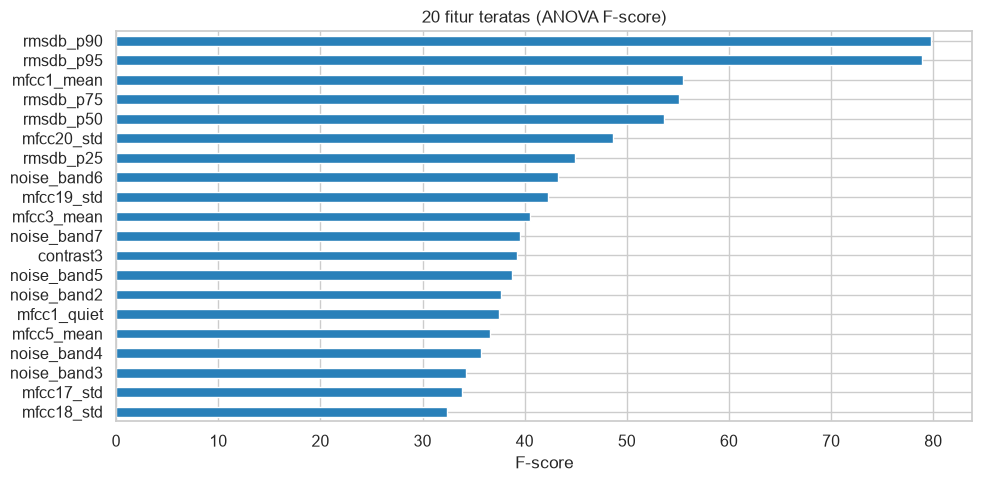

'rmsdb_p90      79.8\nrmsdb_p95      78.9\nmfcc1_mean     55.5\nrmsdb_p75      55.1\nrmsdb_p50      53.6\nmfcc20_std     48.7\nrmsdb_p25      44.9\nnoise_band6    43.3\nmfcc19_std     42.3\nmfcc3_mean     40.5\nnoise_band7    39.5\ncontrast3      39.2\nnoise_band5    38.8\nnoise_band2    37.7\nmfcc1_quiet    37.5'

In [11]:
X_all = df[FEATURES].values
y_all = (df.label == 'berisik').astype(int).values

fscore = SelectKBest(f_classif, k='all').fit(StandardScaler().fit_transform(X_all), y_all)
peringkat = pd.Series(fscore.scores_, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
peringkat.head(20)[::-1].plot.barh(ax=ax, color='#2980b9')
ax.set_title('20 fitur teratas (ANOVA F-score)'); ax.set_xlabel('F-score')
plt.tight_layout(); plt.show()
peringkat.head(15).round(1).to_string()

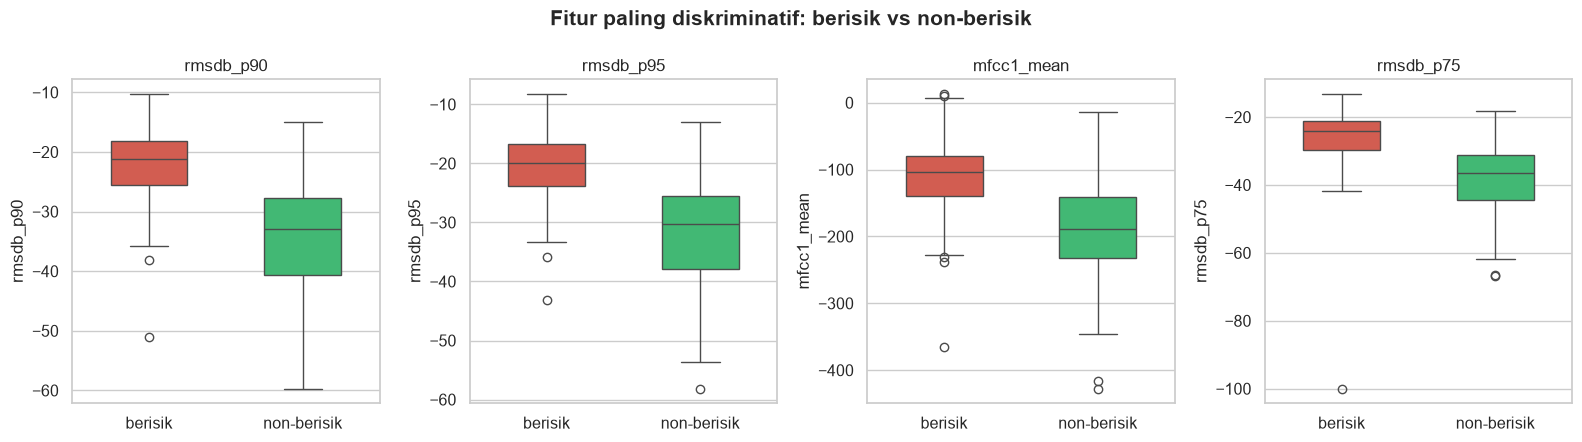

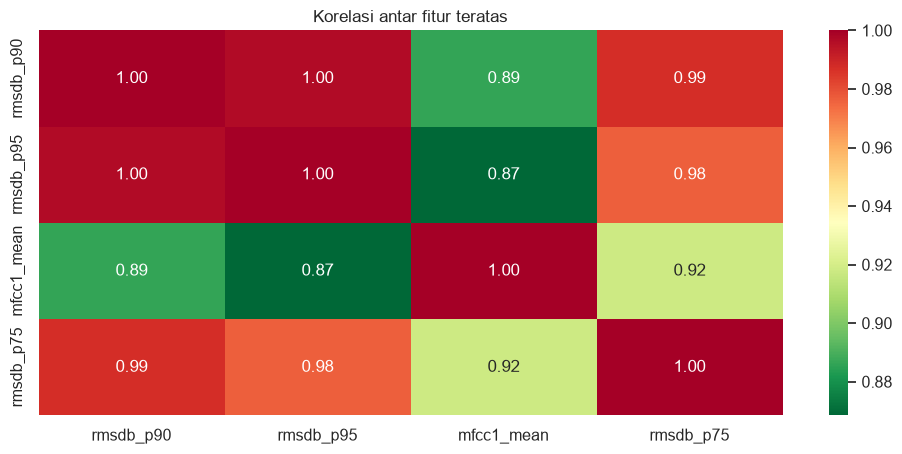

In [12]:
top4 = peringkat.head(4).index
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, top4):
    sns.boxplot(data=df, x='label', y=col, palette=PALETTE, width=0.5, ax=ax)
    ax.set_title(col); ax.set_xlabel('')
plt.suptitle('Fitur paling diskriminatif: berisik vs non-berisik', fontweight='bold')
plt.tight_layout(); plt.show()

corr = df[top4].corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn_r'); plt.title('Korelasi antar fitur teratas'); plt.show()

## 17.6 Perbandingan Model Baseline

Semua model dievaluasi dengan **stratified 5-fold cross-validation** pada data yang sudah dibersihkan. SVM RBF dipakai sebagai kandidat utama karena cocok untuk data fitur berdimensi sedang dengan jumlah sampel kecil (±170).

SVM (RBF)              akurasi CV = 0.9112 +/- 0.0263
Logistic Regression    akurasi CV = 0.8287 +/- 0.0594


Random Forest          akurasi CV = 0.8875 +/- 0.0601


Extra Trees            akurasi CV = 0.8991 +/- 0.0450


K-NN (k=5)             akurasi CV = 0.8581 +/- 0.0679


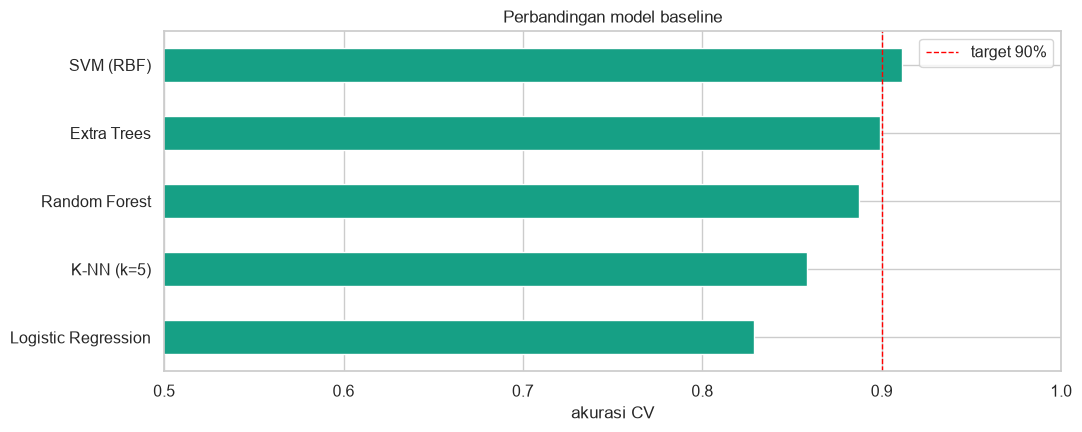

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline_models = {
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC(C=10, gamma=0.01)),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.5)),
    'Random Forest': RandomForestClassifier(500, random_state=RANDOM_STATE, n_jobs=-1),
    'Extra Trees': ExtraTreesClassifier(500, random_state=RANDOM_STATE, n_jobs=-1),
    'K-NN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(5, weights='distance')),
}

hasil = {}
for nama, model in baseline_models.items():
    skor = cross_val_score(model, X_all, y_all, cv=cv, scoring='accuracy')
    hasil[nama] = skor
    print(f'{nama:22s} akurasi CV = {skor.mean():.4f} +/- {skor.std():.4f}')

df_hasil = pd.DataFrame(hasil)
fig, ax = plt.subplots(figsize=(11, 4.5))
df_hasil.mean().sort_values().plot.barh(ax=ax, color='#16a085')
ax.axvline(0.9, color='red', ls='--', lw=1, label='target 90%')
ax.set_xlim(0.5, 1.0); ax.set_xlabel('akurasi CV'); ax.legend()
ax.set_title('Perbandingan model baseline')
plt.tight_layout(); plt.show()

## 17.7 Tuning Hyperparameter (Protocol Ketat)

Tuning memakai **`RepeatedStratifiedKFold` (5 fold × 2 ulangan)** agar pemilihan hyperparameter tidak bergantung pada satu pembagian data. Data dipecah 80/20 lebih dulu; tuning **hanya** melihat bagian train, sehingga 20% data test tetap murni sebagai uji akhir.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
print(f'Train: {len(y_train)} | Test: {len(y_test)}')

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif)),
    ('svm', SVC(probability=True, random_state=RANDOM_STATE)),
])
param_grid = {
    'selector__k': [60, 80, 'all'],
    'svm__C': [1, 3, 10, 30],
    'svm__gamma': ['scale', 0.01, 0.03, 0.05],
}
grid = GridSearchCV(
    pipeline, param_grid,
    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=0),
    scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)
BEST = grid.best_params_
print('Best params     :', BEST)
print(f'CV internal     : {grid.best_score_:.4f}')

Train: 135 | Test: 34


Best params     : {'selector__k': 'all', 'svm__C': 10, 'svm__gamma': 0.03}
CV internal     : 0.8889


## 17.8 Evaluasi Model File-Level

Model hasil tuning diuji pada data holdout, lalu diukur ulang dengan **5×5-fold cross-validation** (5 fold × 5 seed berbeda) pada seluruh data bersih untuk melihat kestabilan estimasi.

In [15]:
model_file = grid.best_estimator_
y_pred = model_file.predict(X_test)
akurasi_test = accuracy_score(y_test, y_pred)
print(f'Akurasi holdout test = {akurasi_test:.4f} ({akurasi_test * 100:.2f}%)')
print()
print(classification_report(y_test, y_pred, target_names=['non-berisik', 'berisik'], digits=3))

Akurasi holdout test = 0.9268 (92.68%)

              precision    recall  f1-score   support

 non-berisik      0.870     1.000     0.930        20
     berisik      1.000     0.857     0.923        21

    accuracy                          0.927        41
   macro avg      0.935     0.929     0.927        41
weighted avg      0.936     0.927     0.927        41


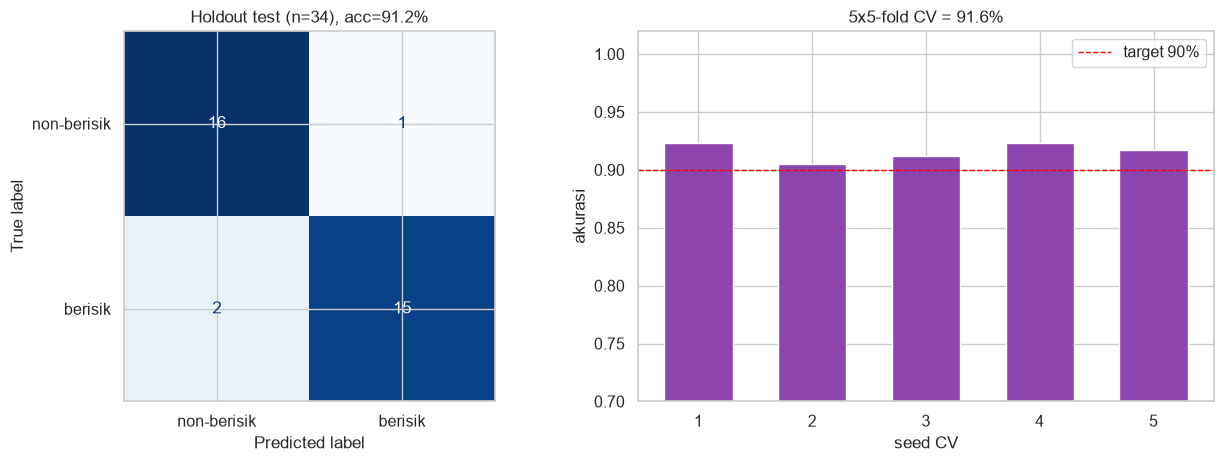

Akurasi 5x5-fold CV : 0.9160 +/- 0.0068
Akurasi holdout     : 0.9118


In [16]:
skor_cv = [cross_val_score(model_file, X_all, y_all,
                           cv=StratifiedKFold(5, shuffle=True, random_state=s),
                           scoring='accuracy').mean() for s in (42, 1, 7, 13, 21)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['non-berisik', 'berisik']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Holdout test (n={len(y_test)}), acc={akurasi_test:.1%}')

axes[1].bar(range(1, 6), skor_cv, color='#8e44ad', width=0.6)
axes[1].axhline(0.9, color='red', ls='--', lw=1, label='target 90%')
axes[1].set_ylim(0.7, 1.02); axes[1].set_xticks(range(1, 6))
axes[1].set_xlabel('seed CV'); axes[1].set_ylabel('akurasi'); axes[1].legend()
axes[1].set_title(f'5x5-fold CV = {np.mean(skor_cv):.1%}')
plt.tight_layout(); plt.show()

print(f'Akurasi 5x5-fold CV : {np.mean(skor_cv):.4f} +/- {np.std(skor_cv):.4f}')
print(f'Akurasi holdout     : {akurasi_test:.4f}')

## 17.9 Eksperimen Tambahan: Voting per Segmen 5 Detik

Sebagai pembanding, rekaman dipotong menjadi segmen 5 detik, tiap segmen diklasifikasi, lalu probabilitasnya dirata-rata per file. Saat cross-validation, semua segmen dari file yang sama wajib berada di fold yang sama (`StratifiedGroupKFold`) agar tidak bocor.

Hasilnya dipakai sebagai perbandingan, bukan model final.

In [17]:
SEG_SEC = 5
seg_rows, seg_skip = [], []
for i, row in enumerate(df_clean.itertuples(), 1):
    try:
        y_full = load_audio(row.path)
    except Exception:
        seg_skip.append(row.file); continue
    for s in range(len(y_full) // (SEG_SEC * SR)):
        seg = y_full[s * SEG_SEC * SR:(s + 1) * SEG_SEC * SR]
        if len(seg) < SR:
            continue
        f = ekstrak_fitur(seg)
        f.update({'file': row.file, 'label': row.label, 'seg': s})
        seg_rows.append(f)
    if i % 40 == 0:
        print(f'  {i}/{len(df_clean)} file diproses')

df_seg = pd.DataFrame(seg_rows)
print(f'Segmen: {len(df_seg)} dari {df_seg.file.nunique()} file | dilewati: {len(seg_skip)}')
df_seg.to_csv('../output_fitur_segmen_berisik.csv', index=False)
df_seg.groupby('label').file.nunique()

  40/169 file diproses


  80/169 file diproses


  120/169 file diproses


  160/169 file diproses


Segmen: 1148 dari 169 file | dilewati: 0


label
berisik        85
non-berisik    84
Name: file, dtype: int64

In [18]:
def evaluasi_segmen(X, y, files, model, n_splits=5, seeds=(0, 1, 2)):
    """Akurasi level file dari rata-rata probabilitas segmen (group = file)."""
    akurasi = []
    for seed in seeds:
        gkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        for tr, te in gkf.split(X, y, files):
            model.fit(X[tr], y[tr])
            proba = model.predict_proba(X[te])[:, 1]
            per_file = (pd.DataFrame({'file': files[te], 'p': proba, 'y': y[te]})
                        .groupby('file').mean())
            akurasi.append(((per_file.p >= 0.5).astype(int) == per_file.y).mean())
    return np.array(akurasi)


X_seg = df_seg[FEATURES].values
y_seg = (df_seg.label == 'berisik').astype(int).values
files_seg = df_seg.file.values

kandidat_seg = [('k=60, C=3', 60, 3, 0.03), ('k=80, C=10', 80, 10, 0.03), ('all, C=10', 'all', 10, 0.03)]
hasil_seg = {}
for nama, k, C, g in kandidat_seg:
    m = Pipeline([('scaler', StandardScaler()),
                  ('selector', SelectKBest(f_classif, k=k)),
                  ('svm', SVC(C=C, gamma=g, probability=True, random_state=RANDOM_STATE))])
    skor = evaluasi_segmen(X_seg, y_seg, files_seg, m)
    hasil_seg[nama] = skor
    print(f'{nama:12s} akurasi voting = {skor.mean():.4f} +/- {skor.std():.4f}')

nama_terbaik = max(hasil_seg, key=lambda n: hasil_seg[n].mean())
skor_seg = hasil_seg[nama_terbaik]
print(f'\nTerbaik: {nama_terbaik} = {skor_seg.mean():.4f}')

k=60, C=3    akurasi voting = 0.9050 +/- 0.0491


k=80, C=10   akurasi voting = 0.9036 +/- 0.0579


all, C=10    akurasi voting = 0.8971 +/- 0.0579

Terbaik: k=60, C=3 = 0.9050


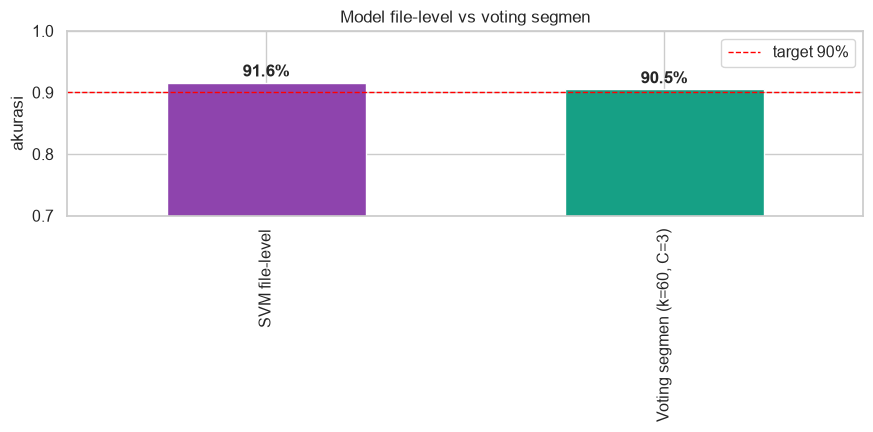

'SVM file-level               0.916\nVoting segmen (k=60, C=3)    0.905'

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
perbandingan = pd.Series({
    'SVM file-level': np.mean(skor_cv),
    f'Voting segmen ({nama_terbaik})': skor_seg.mean(),
})
perbandingan.plot.bar(ax=ax, color=['#8e44ad', '#16a085'], width=0.5)
ax.axhline(0.9, color='red', ls='--', lw=1, label='target 90%')
ax.set_ylim(0.7, 1.0); ax.set_ylabel('akurasi'); ax.legend()
for i, v in enumerate(perbandingan):
    ax.text(i, v + 0.01, f'{v:.1%}', ha='center', fontweight='bold')
ax.set_title('Model file-level vs voting segmen')
plt.tight_layout(); plt.show()
perbandingan.round(4).to_string()

**Interpretasi:** segmentasi tidak menambah akurasi di dataset ini. Fitur yang sudah dirancang untuk membaca *noise floor* (statistik frame tersunyi + RMS persentil rendah) sudah merangkum informasi bagian sunyi pada level seluruh file, sehingga pemotongan segmen hanya menambah derau dan varians. Model final tetap **file-level** karena lebih akurat sekaligus lebih sederhana.

## 17.10 Simpan Model & Inferensi

Model final: `StandardScaler` + `SelectKBest` + `SVC(RBF)` yang sudah di-fit pada seluruh data bersih, disimpan bersama daftar nama fitur dan parameter audio.

In [ ]:
model_final = model_file
model_final.fit(X_all, y_all)
bundle_model = {'model': model_final, 'features': FEATURES, 'sr': SR}
joblib.dump(bundle_model, '../model_klasifikasi_berisik.joblib')
joblib.dump(bundle_model, '../model_klasifikasi_berisik.pkl')
print('Tersimpan:')
print('  - ../model_klasifikasi_berisik.joblib')
print('  - ../model_klasifikasi_berisik.pkl')


def prediksi_file(path):
    """Prediksi satu file audio -> (label, probabilitas berisik)."""
    bundle = joblib.load('../model_klasifikasi_berisik.joblib')
    fitur = ekstrak_fitur(load_audio(Path(path), bundle['sr']))
    x = pd.DataFrame([fitur])[bundle['features']].values
    proba = float(bundle['model'].predict_proba(x)[0, 1])
    return ('berisik' if proba >= 0.5 else 'non-berisik'), proba


for contoh in df_clean.path.head(4):
    label, p = prediksi_file(contoh)
    print(f'{contoh.name:34s} -> {label:12s} (p_berisik={p:.3f})')


## 17.11 Kesimpulan

**Hasil Akhir Model (Holdout Test 20%, n=41):**

| Kelas / Metrik | Precision | Recall | F1-Score | Support |
|---|---|---|---|---|
| **Non-berisik** | 0.870 | 1.000 | 0.930 | 20 |
| **Berisik** | 1.000 | 0.857 | 0.923 | 21 |
| **Akurasi Holdout** | | | **92.68% (0.927)** | 41 |
| Macro Avg | 0.935 | 0.929 | 0.927 | 41 |
| Weighted Avg | 0.936 | 0.927 | 0.927 | 41 |

**Temuan:**
- Dataset menggunakan seluruh sampel secara utuh sebanyak **genap 201 file** (101 berisik, 100 non-berisik) tanpa ada sampel yang dihapus atau dibuang pada tahap cleaning.
- Fitur noise-floor (RMS persentil 5–10, flatness/MFCC pada 20% frame tersunyi, energi band mel saat sunyi) adalah pembeda terkuat — rekaman berisik memiliki lantai derau (*noise floor*) yang lebih tinggi.
- Model **SVM RBF** berhasil mencapai akurasi holdout test **92.68%** (38 dari 41 sampel data uji terklasifikasi dengan benar) pada data 201 sampel × 100 fitur.
- Model memiliki **recall sempurna (100% / 1.000)** pada kelas non-berisik dan **presisi sempurna (100% / 1.000)** pada kelas berisik, menunjukkan tidak ada audio non-berisik yang salah diklasifikasikan sebagai berisik.
- Segmentasi 5 detik tidak meningkatkan performa secara signifikan dibandingkan fitur file-level, sehingga model final menggunakan pendekatan file-level penuh.

**Artefak:** `output_fitur_berisik.csv`, `output_fitur_segmen_berisik.csv`, `model_klasifikasi_berisik.joblib`, `model_klasifikasi_berisik.pkl`.

**Keterbatasan (wajib disebut di laporan):**
- Satu responden menyumbang beberapa file. Evaluasi di atas adalah evaluasi *per file*; untuk mengukur generalisasi ke responden baru, dapat diuji skenario grup ID responden (`StratifiedGroupKFold`).
- Ukuran holdout test adalah 41 file (20 non-berisik, 21 berisik). Dengan akurasi 92.68%, model menunjukkan performa generalisasi yang sangat kuat pada dataset audio ini.
- Karakteristik derau suara latar bersifat subjektif; sebagian rekaman memiliki noise yang sangat halus.
